In [1]:
import numpy as np
import matplotlib.pyplot as plt
import dask.dataframe as dd
import trenchripper as tr
import pandas as pd

%matplotlib inline

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.0' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
# addition of active memory manager
import dask
dask.config.set({'distributed.scheduler.active-memory-manager.start': True});
dask.config.set({'distributed.scheduler.worker-ttl': "5m"});
dask.config.set({'distributed.scheduler.allowed-failures': 100});

dask_wd = "/home/lag36/scratch/lag36/dask"

In [3]:
dask_controller = tr.trcluster.dask_controller(
    walltime="3:00:00",
    local=False,
    n_workers=20,
    n_workers_min=20,#200,
    memory="8GB",
    working_directory=dask_wd,
)
dask_controller.startdask()

# dask_controller = tr.trcluster.dask_controller(
#     walltime="2:00:00",
#     local=False,
#     n_workers=50,
#     n_workers_min=50,
#     memory="8GB",
#     working_directory=dask_wd,
# )
# dask_controller.startdask()

170m
3:00:00


In [4]:
dask_controller.daskclient

Connection method: Cluster object,Cluster type: dask_jobqueue.SLURMCluster
Dashboard: http://10.120.16.38:8787/status,
Dashboard: http://10.120.16.38:8787/status,Workers: 0
Total threads: 0,Total memory: 0 B
Comm: tcp://10.120.16.38:43604,Workers: 0
Dashboard: http://10.120.16.38:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B


In [13]:
dask_controller.shutdown()

Done.


2025-01-20 11:48:00,090 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [6]:
import pandas as pd
headpath = "/home/lag36/scratch/lag36/2024-12-12_lLAG8_EZRDM_Run-02_3-Fiducials_Auto-Media-Switch/Barcodes"
df_2_1 = pd.read_hdf(headpath+'/barcode_output_df_fiducials_hamming-0_rm-1-28.hdf5')
df_2_1

,trenchid,Barcode Signal,Barcode,consensus,reference,alignmentstart,cigar,subsample,barcode depth,closest_match,...,locus_tag,offset,Gene,sgRNA Sequence,Target Sequence,Category,Predicted_Efficacy,TargetID,barcode,barcodeid
0,3113,"[6210.599999999999, 0.0, 6723.799999999999, 59...",101111111011000110111110100100,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,4523.0,3,...,BSU_15680,369.0,gmk,CAGAAACGCTTGGAGGCGCA,TGCGCCTCCAAGCCTTTCTG,essential,0.833878,765.0,101111110100111100111101100100,85093
1,3242,"[2608.0, 0.0, 7769.08, 2427.18, 2406.02, 2327....",001000000100010001110001100101,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,966.0,4,...,BSU_33910,292.0,pgm,TCCCGTTGCTGATCGCGTCA,TGACGCGATCAGCAACGCGA,essential,0.818116,1728.0,000000101101001000000001011101,1148
2,3445,"[4139.0599999999995, 0.0, 2259.08, 3891.2, 411...",100110101001010110110011101101,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,522.0,3,...,NaN,NaN,NaN,AGAGCATAATCCGGATATCC,GGATATCCGGATTATGCTCT,control,NaN,2788.0,101101010101101000100111101101,80266
3,4037,"[8144.12, 0.0, 2936.02, 2749.0, 2744.02, 8915....",100001000110111111111001000000,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,3641.0,3,...,BSU_23380,97.0,lysA,GCCACATCATATACGTAAAC,CTTTACGTATATGATGTGGC,auxotroph,0.083748,2226.0,101110001111011110000000011000,112925
4,4290,"[2419.1, 0.0, 2408.02, 3955.06, 2349.02, 2327....",000100000111110011110010011100,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,831M1I260M,NaN,536.0,4,...,BSU_29470,6.0,ackA,CGCGTTAATTGCAATAATTT,AAATTATTGCAATTAACGCA,essential,0.866134,1577.0,000111011111001001000111010000,11836
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
269480,1336701,"[8065.04, 0.0, 2401.06, 2287.0, 2293.0, 2264.0...",100000000110101000101110100000,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,511M1D579M,NaN,855.0,4,...,BSU_11010,1146.0,yitJ,TACGGTCACGGCACGTAATT,TATTACGTGCCGTGACCGTA,auxotroph,0.388514,2059.0,100010000110000110001100010100,88590
269481,1337427,"[2162.0, 0.0, 6547.02, 6186.48, 2071.02, 2060....",001100010101101110010101101001,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,247.0,3,...,BSU_28290,386.0,ilvC,CAACTGTCCCGGGCCTTTAG,CTAAAGGCCCGGGACACTTG,auxotroph,0.809468,2258.0,001101110010001010011010011101,23605
269482,1338988,"[2354.02, 0.0, 2363.0, 2208.08, 2303.0, 2216.0...",000000011110010001111100001101,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,562.0,2,...,BSU_00020,217.0,dnaN,GCCTGTAAAACGACGCTTCC,GGAAGCATCGTTTTACAGGC,essential,0.575392,12.0,000010001101001100011011110001,3328
269483,1339439,"[2267.0, 0.0, 2305.02, 2176.02, 10051.27999999...",000010001010001100101100110101,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,2881.0,4,...,BSU_16750,402.0,asd,GTTCAAGTGCCGCAACAATT,AATGGTTGCGGCACTTGAAC,essential,0.469439,991.0,001010000100100111001001100101,16837


In [6]:
# Translates from dd to df
bc_kymo_metadata = dd.read_parquet(headpath+"/kymograph/metadata", calculate_divisions=True)
bc_kymo_metadata_df = bc_kymo_metadata.compute()
# Change the type of the lane orientation column to category
bc_kymo_metadata_df["lane orientation"] = bc_kymo_metadata_df["lane orientation"].astype(object)
bc_kymo_metadata_df.to_hdf(headpath+"/kymograph_metadata_df.hdf5", key='data')

In [7]:
bc_kymo_metadata_df = pd.read_hdf(headpath+"/kymograph_metadata_df.hdf5", key='data')

In [8]:
df_lookup = (df_2_1
             .loc[:,['trenchid', 'Barcode Signal', 'Barcode', 'closest_match',  'barcode depth', 'Closest Hamming Distance', 'Category', 'barcode', 'barcodeid']]
             .merge(bc_kymo_metadata_df.groupby('trenchid').first().reset_index(),
                    left_on='trenchid',
                    right_on='trenchid', how='left')
                )

In [9]:
### QC segmentation
import h5py
import matplotlib.pyplot as plt
import numpy as np

def show_kymograph(
        path_prefix,
        path_kymo_dir_prefix,
        channels,
        cmap,
        kymo_file_index,
        trench_index,
        t_indices,
        figsize,
        Barcode = None,
        barcode_phe = None #translated from seq barcode
        ):
    
    n_cycles_per_ch = 15 # TODO GENERALIZE
    with h5py.File(path_prefix + path_kymo_dir_prefix + str(kymo_file_index) + ".hdf5", "r") as infile:
        for i_ch, ch in enumerate(channels):
            img = infile[ch][trench_index][t_indices[0]]
            for ind in t_indices[1:]:
                img_ind = infile[ch][trench_index][ind]
                img = np.concatenate((img, img_ind), axis=1)
            plt.figure(figsize=figsize)
            # Do not show axes ticks
            plt.xticks([])
            plt.yticks([])
            plt.imshow(img, cmap=cmap, aspect=1)
            # Annotate the kymo_file_index and the trench index at the bottom left corner
            plt.annotate(f'kymo_file_index: {kymo_file_index}, trench index: {trench_index}', (10, 15), color='white')
            # Annotate the cycle number at the bottom of each slice
            for i, ind in enumerate(t_indices):
                # plt.annotate(f'{ind}', (i*9+9/4, 160), color='white', fontsize=8) # 13 is the width of a slice
                plt.annotate(f'{ind}', (i*11+11/4, 160), color='white', fontsize=8) # 13 is the width of a slice
            # Annotate the Barcode bit at the bottom of each slice
            if Barcode is not None:
                
                for i, bit in enumerate(Barcode[i_ch*n_cycles_per_ch:(i_ch+1)*n_cycles_per_ch]):
                    # plt.annotate(f'{bit}', (i*9+9/3, 140), color='yellow', fontsize=8) # 13 is the width of a slice
                    plt.annotate(f'{bit}', (i*11+11/3, 140), color='yellow', fontsize=8) # 13 is the width of a slice
            # Annotate the barcode bit at the bottom of each slice
            if barcode_phe is not None:
                for i, bit in enumerate(barcode_phe[i_ch*n_cycles_per_ch:(i_ch+1)*n_cycles_per_ch]):
                    # plt.annotate(f'{bit}', (i*9+9/3, 120), color='red', fontsize=8) # 13 is the width of a slice
                    plt.annotate(f'{bit}', (i*11+11/3, 120), color='red', fontsize=8) # 13 is the width of a slice
            plt.show()
            plt.close()

def map_bc_to_pheno(barcode,
                    cycleorder = [0,1,6,7,12,13,18,19,24,25,4,5,10,11,16,
                                  2,3,8,9,14,15,20,21,26,27,17,22,23,28,29],
                    ):
    barcode_phe = [-1]*30
    for i, bit in enumerate(barcode):
        # print(i, bit)
        # Find the position of i in cycleorder
        i_phe = cycleorder.index(i)
        barcode_phe[i_phe] = bit
    barcode_phe = ''.join(barcode_phe)
    return barcode_phe

In [8]:
a = df_lookup.loc[df_lookup['Category'] == 'fiducial', 'Barcode'].value_counts()

In [ ]:
a

In [ ]:
a[a == 4]

In [ ]:
df_lookup[df_lookup['closest_match'] <= 10]

In [ ]:
df_lookup.loc[df_lookup['Barcode'] == '111111111111111111111111101110']

In [ ]:
df_lookup.loc[df_lookup['Barcode'] == '111111111111111111111111101110', 'Category']

In [11]:
df_lookup.columns

Index(['trenchid', 'Barcode Signal', 'Barcode', 'closest_match',
       'barcode depth', 'Closest Hamming Distance', 'Category', 'barcode',
       'barcodeid', 'fov', 'row', 'trench', 'timepoints', 'time (s)',
       'lane orientation', 'y (local)', 'x (local)', 'y (global)',
       'x (global)', 'Global Row', 'File Index', 'File Trench Index',
       'File Parquet Index', 'Trenchid Timepoint Index'],
      dtype='object')

In [ ]:
df

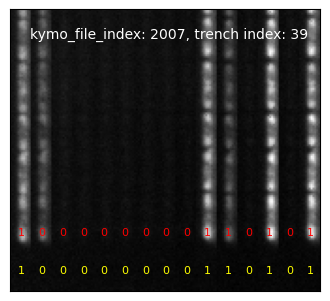

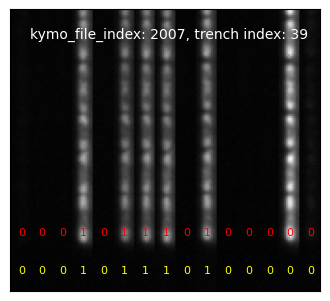

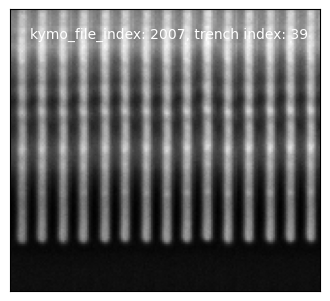

In [12]:
trenchid = 1336701
bc_kymo_file_index, bc_trench_index, Barcode, barcode = df_lookup.loc[df_lookup['trenchid'] == trenchid, ['File Index', 'File Trench Index', 'Barcode', 'barcode']].values[0]
bc_kymo_file_index = int(bc_kymo_file_index)
bc_trench_index = int(bc_trench_index)
# barcode (lowercase) comes from sequencing (red)
# Barcode (uppercase) comes from trench signal (yellow)
# Barcode, barcode = df_lookup.loc[row, ['Barcode', 'barcode']]
barcode_phe = map_bc_to_pheno(barcode)
figsize = (4, 8)
path_prefix = headpath+"/"
path_kymo_dir_prefix = "kymograph/kymograph_"
# channels = ["BF", "RFP", "Cy5"]
channels = ["RFP", "Cy5"]
cmap = "gray"
t_indices = np.arange(0,15)
show_kymograph(path_prefix, path_kymo_dir_prefix, channels, cmap, bc_kymo_file_index, bc_trench_index, t_indices, figsize, Barcode, barcode_phe)
show_kymograph(path_prefix, path_kymo_dir_prefix, ['BF'], cmap, bc_kymo_file_index, bc_trench_index, t_indices, figsize, None, None)